In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from skimage import io

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import classification_report

from keras.models import Sequential
from keras.layers import Input, Dense, Flatten, Conv2D, MaxPooling2D, Dropout
from keras.constraints import MaxNorm
from keras.optimizers import SGD

In [2]:
import os
os.chdir(r'C:\Users\gonza\Desktop\Desafío Latam\G76\6. Modelos Avanzados y Redes Neuronales\6. 06-11-2024\Apoyo Desafío - Procesamiento y redes recurrentes (Parte I)\DataSet')
os.listdir()

['cnn_pred_X.npy',
 'cnn_test_X.npy',
 'cnn_test_y.npy',
 'cnn_train_X.npy',
 'cnn_train_y.npy']

Funcion para visualizar una seleccion aleatoria de imagenes con sus etiquetas correspondientes en una cuadricula, útil para exploración visual del dataset.

In [3]:
def show_images(X_img, y_img, nrow=3, ncol=3):
    fig, ax = plt.subplots(nrows=nrow, ncols=ncol, figsize=(4 + ncol, 4 + nrow/2.5),
                          sharex=True, sharey=True)

    for i in range(nrow):
        for j in range(ncol):
            alea = np.random.randint(0, X_img.shape[0]+1)
            #print(alea)
            ax[i, j].set_title(y_img[alea])
            ax[i, j].imshow(X_img[alea])
            ax[i, j].set_title(y_img[alea])
            ax[i, j].set_axis_off()
    plt.tight_layout()
    plt.show();

In [4]:
X_train = np.load('cnn_train_X.npy', allow_pickle=True)
y_train = np.load('cnn_train_y.npy', allow_pickle=True)
X_test = np.load('cnn_test_X.npy', allow_pickle=True)
y_test = np.load('cnn_test_y.npy', allow_pickle=True)
X_pred = np.load('cnn_pred_X.npy', allow_pickle=True)

print('='*20 + '\n')
print('{:<12}{:>5}'.format('X_train', X_train.shape[0]))
print()
print(pd.Series(y_train).value_counts())
print('-'*20 + '\n')

print('{:<12}{:>5}'.format('X_test', X_test.shape[0]))
print()
print(pd.Series(y_test).value_counts())
print('-'*20)

print('\n'+'='*20)


X_train     14034

mountain     2512
glacier      2404
street       2382
sea          2274
forest       2271
buildings    2191
Name: count, dtype: int64
--------------------

X_test       3000

glacier      553
mountain     525
sea          510
street       501
forest       474
buildings    437
Name: count, dtype: int64
--------------------



In [5]:
# Acá tienes las etiquetas
print()
print(pd.Series(y_train).value_counts())


mountain     2512
glacier      2404
street       2382
sea          2274
forest       2271
buildings    2191
Name: count, dtype: int64


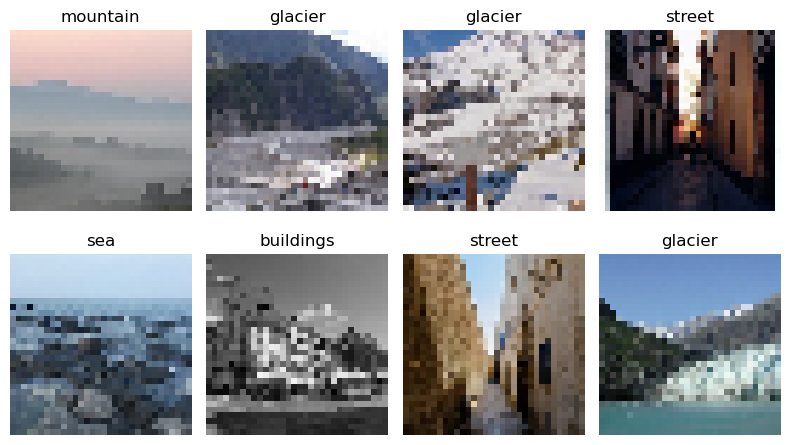

In [6]:
show_images(X_train, y_train, nrow=2, ncol=4)

Transformación de etiquetas categóricas (como números o texto) a formato one-hot (vectores binarios) para el entrenamiento en redes neuronales

```python
one_hot = OneHotEncoder()
```
- Crea una instancia del codificador de scikit-learn que transformará valores categóricos en vectores binarios.

```python
y_train = one_hot.fit_transform(y_train.reshape(-1, 1)).toarray()
```
- `y_train.reshape(-1, 1)`: Convierte el array 1D de etiquetas en una matriz de columna única (requisito de scikit-learn)
- `one_hot.fit_transform()`: Analiza las categorías únicas y convierte cada valor en un vector de ceros con un único 1
- `.toarray()`: Convierte la matriz dispersa resultante en un array NumPy denso

```python
y_test = one_hot.fit_transform(y_test.reshape(-1, 1)).toarray()
```
- Aplica el mismo proceso a las etiquetas de prueba.

##### Ejemplo
Si las etiquetas originales son [0, 2, 1] (representando 3 clases):

Después de la codificación one-hot:
```python
- [0] → [1, 0, 0]
- [2] → [0, 0, 1]
- [1] → [0, 1, 0]
```

In [7]:
one_hot = OneHotEncoder()
y_train = one_hot.fit_transform(y_train.reshape(-1, 1)).toarray()
y_test = one_hot.fit_transform(y_test.reshape(-1, 1)).toarray()

In [9]:
y_train[0]

array([0., 1., 0., 0., 0., 0.])

In [10]:
y_test

array([[0., 1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 1., 0.]])

Definimos una arquitectura de red neuronal para clasificacion multiclase, la cual me va a ayudar a resolver un problema de clasificacion con 6 categorías diferentes.

Lo que hace la arquitectura es lo siguiente convertir datos complejos a una representación plana, procesarlos a través de capas densas con regularización, y finalmente producir una distribución de probabilidad sobre las posibles clases.

##### Detalle especifico de la arquitectura de la red neuronal

```python
fcnn.add(Input(shape=(X_train.shape[1], X_train.shape[2], X_train.shape[3])))
```
Añadimos la capa de entrada, que define la forma de los datos que la red procesará


```python
fcnn.add(Flatten())
```
capa que transforma los datos multidimensionales en un vector unidimensional


```python
fcnn.add(Dense(units=1024, activation='relu', use_bias=True, kernel_initializer='glorot_normal'))
```
Añadimos una capa densa de 1024 neuronas, La función de activación ReLU, que permite modelar relaciones no lineales, Inicializa los pesos usando el método "glorot_normal", que ayuda a que el entrenamiento sea más estable y eficiente

```python
fcnn.add(Dropout(rate=.2))
```
Apagamos aleatoriamente el 20% de las neuronas


```python
fcnn.add(Dense(units=6, activation='softmax', use_bias=True, kernel_initializer='glorot_normal'))
```
Capa de salida: Tiene exactamente 6 neuronas, una por cada clase posible, Usa la función de activación softmax, que convierte los valores en probabilidades que suman 1.0, cada valor de salida representa la probabilidad estimada de que la entrada pertenezca a esa clase

```python
fcnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
```
##### configuramos el aprendizaje del modelo
- La entropía cruzada categórica es la elección ideal para problemas de clasificación multiclase donde las etiquetas están en formato one-hot y las metricas que se calcularan durante el entrenamiento y la evaluacion es 'accuracy'


```python
fcnn.summary()
```
generamos un resumen detallado de la arquitectura del modelo

In [16]:
# Ejemplo de una red que podrían implementar
# Esta es la red fully connected
# Agregar más capas, más neuronas, cambiar las activaciones, etc.

n_class = 6                                                                                        # numero de clases de salida
fcnn = Sequential()                                                           
fcnn.add(Input(shape=(X_train.shape[1], X_train.shape[2], X_train.shape[3])))                      
fcnn.add(Flatten())                                                                                
fcnn.add(Dense(units=1024, activation='relu', use_bias=True, kernel_initializer='glorot_normal'))   
fcnn.add(Dropout(rate=.2))                                                                         

# 6 por la cantidad de clases
fcnn.add(Dense(units=6, activation='softmax', use_bias=True, kernel_initializer='glorot_normal'))  

fcnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])              
fcnn.summary()                                                                                     

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_2 (Flatten)         (None, 3072)              0         
                                                                 
 dense_2 (Dense)             (None, 1024)              3146752   
                                                                 
 dropout (Dropout)           (None, 1024)              0         
                                                                 
 dense_3 (Dense)             (None, 6)                 6150      
                                                                 
Total params: 3152902 (12.03 MB)
Trainable params: 3152902 (12.03 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


Procedemos a implementar el proceso de entrenamiento y evaluacion de la red neuronal previamente definida.

```python
fcnn.fit(X_train, y_train, batch_size=50, epochs=epochs, validation_data=(X_test, y_test))
```
Ejecutamos el proceso de entrenamiento con los siguiente parametros
- Datos de entrada: X_train (imágenes) y y_train (etiquetas one-hot)
- batch_size=50: Procesa los datos en grupos de 50 muestras a la vez
- epochs=epochs: Realiza 50 ciclos completos de entrenamiento
- validation_data=(X_test, y_test): Durante el entrenamiento, evalua el rendimiento del modelo en datos que no ha visto. Proporciona informacion sobre posible sobreajuste. Muestra la evolución de la precisión y pérdida en datos de validación.

```python
score = fcnn.evaluate(X_test, y_test, verbose=0)
```
Evalua el rendimiento final del modelo en el conjunto de prueba
- Calcula tanto la perdida como la precision
- `verbose=0` suprime la salida detallada durante la evaluación.
- Devuelve un array donde el primer elemento es la pérdida y el segundo es la precisión

In [17]:
# Podrían ponerle más épocas
# Cambiar tamaño de la batch
epochs = 50
fcnn.fit(X_train, y_train, batch_size=50, epochs=epochs, validation_data=(X_test, y_test))
score = fcnn.evaluate(X_test, y_test, verbose=0)
print(f'Test accuracy: {score[1]}')

Epoch 1/50
141/141 [==============================] - 2s 14ms/step - loss: 1.7337 - accuracy: 0.4135 - val_loss: 1.4379 - val_accuracy: 0.4487
Epoch 2/50
141/141 [==============================] - 2s 12ms/step - loss: 1.2863 - accuracy: 0.5107 - val_loss: 1.2472 - val_accuracy: 0.5290
Epoch 3/50
141/141 [==============================] - 2s 12ms/step - loss: 1.2218 - accuracy: 0.5298 - val_loss: 1.2335 - val_accuracy: 0.5387
Epoch 4/50
141/141 [==============================] - 2s 12ms/step - loss: 1.1768 - accuracy: 0.5519 - val_loss: 1.2070 - val_accuracy: 0.5417
Epoch 5/50
141/141 [==============================] - 2s 12ms/step - loss: 1.1574 - accuracy: 0.5570 - val_loss: 1.1675 - val_accuracy: 0.5520
Epoch 6/50
141/141 [==============================] - 2s 12ms/step - loss: 1.1468 - accuracy: 0.5651 - val_loss: 1.1902 - val_accuracy: 0.5477
Epoch 7/50
141/141 [==============================] - 2s 12ms/step - loss: 1.1221 - accuracy: 0.5770 - val_loss: 1.1680 - val_accuracy: 0.5550

##### Evaluacion del rendimiento del modelo

```python
yhat_test = fcnn.predict(X_test)
```
- Utiliza el modelo entrenado para generar predicciones sobre el conjunto de prueba
- yhat_test es una matriz donde cada fila contiene las probabilidades predichas para cada una de las 6 clases
- Por ejemplo: [0.05, 0.1, 0.7, 0.05, 0.05, 0.05] indicaría 70% de confianza en la clase 2

```python
decoded_y_test = y_test.argmax(axis=1)
```
- Convierte las etiquetas one-hot (ej: [0,0,1,0,0,0]) a su forma numérica (ej: 2)
- argmax(axis=1) encuentra el índice del valor máximo (1) en cada fila
- Esta conversión es necesaria para usar las funciones de evaluación de scikit-learn (como classification_report)

```python
decoded_yhat = yhat_test.argmax(axis=1)
```
- Similar al paso anterior, pero aplicado a las predicciones del modelo
- Transforma las probabilidades a decisiones concretas, seleccionando la clase con mayor probabilidad
- El resultado es un array de índices que representan la clase predicha para cada muestra

```python
print(classification_report(decoded_y_test, decoded_yhat, zero_division=np.nan))
```
Generamos el informe de clasificación
- El parámetro zero_division=np.nan maneja casos donde una clase podría no tener ejemplos, evitando errores de división por cero


-----------------------


##### Explicación más detallada del código:
```python
decoded_y_test = y_test.argmax(axis=1)
```
Esta línea de código convierte etiquetas codificadas en formato one-hot a sus índices de clase correspondientes.
- `argmax()`: Función de NumPy que encuentra la posición del valor máximo en un array
- `axis=1`: Especifica que la operación debe realizarse a lo largo de cada fila individualmente
- El resultado es un array unidimensional donde cada valor representa el índice de la clase

Ejemplo concreto:
Si tenemos una matriz one-hot como:
```python
y_test = [
  [0, 1, 0, 0, 0, 0],  # Muestra 1: Clase 1
  [0, 0, 0, 0, 1, 0],  # Muestra 2: Clase 4
  [1, 0, 0, 0, 0, 0]   # Muestra 3: Clase 0
]
```
Después de aplicar `y_test.argmax(axis=1)`, obtenemos:
```python
decoded_y_test = [1, 4, 0]
```

##### Propósito
Esta transformación es necesaria porque las funciones de evaluación de scikit-learn (como `classification_report`) requieren etiquetas en formato de índice numérico, no en formato one-hot. Esta conversión permite comparar directamente las clases predichas con las reales.

La operación es crucial para el análisis posterior ya que transforma la representación matemática utilizada por la red neuronal a una forma interpretable para las métricas de evaluación.

##### Por otro lado, este codigo sigo una instruccion casi similiar
```python
decoded_yhat = yhat_test.argmax(axis=1)
```
Esta línea de código transforma las predicciones probabilísticas del modelo a etiquetas de clase específicas.
- `argmax()`: Función de NumPy que identifica la posición del valor máximo en un array
- `axis=1`: Indica que la operación debe ejecutarse por filas (para cada muestra individual)
- El resultado es un array unidimensional que contiene los índices de las clases predichas

##### Ejemplo concreto
Si tenemos una matriz de probabilidades como:
```python
yhat_test = [
  [0.03, 0.87, 0.05, 0.02, 0.01, 0.02],  # Muestra 1: Probabilidades para 6 clases
  [0.10, 0.05, 0.02, 0.03, 0.75, 0.05],  # Muestra 2: Probabilidades para 6 clases
  [0.91, 0.02, 0.01, 0.02, 0.03, 0.01]   # Muestra 3: Probabilidades para 6 clases
]
```
Después de aplicar `yhat_test.argmax(axis=1)`, obtenemos:
```python
decoded_yhat = [1, 4, 0]
```
##### Propósito
Esta transformación convierte las predicciones probabilísticas (salida de la capa softmax) en decisiones discretas de clasificación, seleccionando la clase con mayor probabilidad asignada por el modelo. Es esencial para:
- Convertir el formato de salida del modelo a un formato compatible con las métricas de evaluación
- Permitir la comparación directa con las etiquetas reales (decoded_y_test)
- Posibilitar el cálculo de métricas como precisión, recall y F1-score en el informe de clasificación

Esta operación representa el paso final del proceso de decisión del modelo, donde las probabilidades estimadas se convierten en clasificaciones concretas.

In [18]:
yhat_test = fcnn.predict(X_test)

decoded_y_test = y_test.argmax(axis=1)
decoded_yhat = yhat_test.argmax(axis=1)

print(classification_report(decoded_y_test, decoded_yhat, zero_division=np.nan))

94/94 [==============================] - 0s 2ms/step
              precision    recall  f1-score   support

           0       0.54      0.35      0.42       437
           1       0.77      0.73      0.75       474
           2       0.57      0.62      0.59       553
           3       0.50      0.75      0.60       525
           4       0.56      0.33      0.42       510
           5       0.61      0.71      0.65       501

    accuracy                           0.59      3000
   macro avg       0.59      0.58      0.57      3000
weighted avg       0.59      0.59      0.57      3000



##### Definición de la arquitectura de la Red Neuronal Convolucional (CNN)
```python
cnn1.add(Input(shape=(X_train.shape[1], X_train.shape[2], X_train.shape[3])))
```
- Definimos la capa de entrada con dimensiones que coinciden con las imágenes de entrenamiento
- Para imágenes, típicamente representa (altura, anchura, canales de color)

```python
cnn1.add(Conv2D(filters=16, kernel_size=(3, 3), strides=(1, 1), padding='same', activation='relu', use_bias=True, kernel_constraint=MaxNorm(3), kernel_initializer='glorot_normal'))
```
Primera capa convolucional:
- 16 filtros que aprenderán a detectar diferentes características
- Ventana de 3×3 píxeles que escanea la imagen
- Desplazamiento de 1 píxel en cada paso
- Padding 'same' mantiene las dimensiones espaciales originales
- Activación ReLU para introducir no linealidad
- Restricción MaxNorm(3) limita el crecimiento excesivo de los pesos
- Inicialización Glorot normal para una convergencia más estable

```python
cnn1.add(Conv2D(filters=16, kernel_size=(3, 3), strides=(1, 1), padding='same', activation='relu', use_bias=True, kernel_constraint=MaxNorm(3), kernel_initializer='glorot_normal'))
```
- Segunda capa convolucional con configuración idéntica
- Apilar capas convolucionales permite detectar patrones más complejos

```python
cnn1.add(MaxPooling2D(pool_size=(2, 2), strides=(1, 1)))
```
Capa de max pooling:
- Reduce las dimensiones espaciales seleccionando el valor máximo en cada ventana de 2×2
- Desplazamiento de 1×1
- Proporciona cierta invarianza a pequeñas traslaciones en la imagen
- Reduce el número de parámetros en las capas siguientes

##### Ejemplo Visual con estos Parámetros
Entrada original:
```python
[ 1  7  3  0 ]
[ 5  2  6  8 ]
[ 3  5  7  1 ]
[ 9  4  2  7 ]
```
Después del MaxPooling2D con pool_size=(2, 2), strides=(1, 1):
```python
[ 7  7  8 ]
[ 5  7  8 ]
[ 9  7  7 ]
```
##### Efectos de esta Configuración
- Reducción dimensional mínima: La salida es solo ligeramente menor que la entrada (si la entrada es de tamaño n×n, la salida será (n-1)×(n-1))
- Alta preservación de información: Al mover la ventana solo un píxel por vez, se mantiene más información espacial
- Mayor robustez a la posición: Extrae características con un alto grado de superposición, lo que mejora la invarianza a pequeñas traslaciones

Esta configuración particular sacrifica la reducción dimensional drástica (ventaja tradicional del MaxPooling) a favor de preservar más información espacial mientras mantiene los beneficios de extracción de características dominantes.



```python
# Siempre debe ir un flatten antes de entrar a una red convencional
cnn1.add(Flatten())
```
- Transforma la salida 3D de las capas convolucionales en un vector 1D
- Paso obligatorio antes de conectar con capas densas (completamente conectadas)

```python
cnn1.add(Dense(units=256, activation='relu', use_bias=True, kernel_constraint=MaxNorm(3), kernel_initializer='glorot_normal'))
```
Capa densa intermedia:
- 256 neuronas que combinan las características extraídas
- Activación ReLU
- Restricción MaxNorm(3) para regularización

```python
cnn1.add(Dense(units=n_class, activation='softmax', use_bias=True, kernel_initializer='glorot_normal'))
```
Capa de salida:
- 6 neuronas (una por cada clase)
- Activación softmax que convierte las salidas en probabilidades que suman 1
- La clase con mayor probabilidad será la predicción final

```python
cnn1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn1.summary()
```
Compilación del modelo:
- Optimizador Adam para ajustar los pesos eficientemente
- Función de pérdida de entropía cruzada categórica para clasificación multiclase
- Métrica de precisión para evaluar el rendimiento

Resumen: Muestra la arquitectura completa con formas de salida y número de parámetros

Esta CNN es más sofisticada que la red anterior (fcnn) porque aprovecha la estructura espacial de las imágenes mediante capas convolucionales antes de pasar a capas densas.

In [22]:
# Ejemplo de una red convolucional

n_class = 6               # establecemos el número de categorías a clasificar
cnn1 = Sequential()       # creamos un modelo secuencial vacio
cnn1.add(Input(shape=(X_train.shape[1], X_train.shape[2], X_train.shape[3])))
cnn1.add(Conv2D(filters=16, kernel_size=(3, 3), strides=(1, 1), padding='same', activation='relu', use_bias=True, kernel_constraint=MaxNorm(3), kernel_initializer='glorot_normal'))
cnn1.add(Conv2D(filters=16, kernel_size=(3, 3), strides=(1, 1), padding='same', activation='relu', use_bias=True, kernel_constraint=MaxNorm(3), kernel_initializer='glorot_normal'))
cnn1.add(MaxPooling2D(pool_size=(2, 2), strides=(1, 1)))
# Siempre debe ir un flatten antes de entrar a una red convencional
cnn1.add(Flatten())
cnn1.add(Dense(units=256, activation='relu', use_bias=True, kernel_constraint=MaxNorm(3), kernel_initializer='glorot_normal'))
cnn1.add(Dense(units=n_class, activation='softmax', use_bias=True, kernel_initializer='glorot_normal'))


cnn1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn1.summary()


Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_2 (Conv2D)           (None, 32, 32, 16)        448       
                                                                 
 conv2d_3 (Conv2D)           (None, 32, 32, 16)        2320      
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 31, 31, 16)        0         
 g2D)                                                            
                                                                 
 flatten_3 (Flatten)         (None, 15376)             0         
                                                                 
 dense_6 (Dense)             (None, 256)               3936512   
                                                                 
 dense_7 (Dense)             (None, 6)                 1542      
                                                      

Procedemos a entrenar y a evaluar la red neuronal convolucional definida anteriormente
`epochs = 15` -> definimos el numero total de ciclos de entrenamiento completo

```python
cnn1_history = cnn1.fit(X_train, y_train, batch_size=164, epochs=epochs, validation_data=(X_test, y_test))
```
- `fit()`: Ejecuta el algoritmo de entrenamiento
- `X_train, y_train`: Datos de imágenes y etiquetas para entrenamiento
- `batch_size=164`: Procesa 164 imágenes simultáneamente en cada iteración, lo que:
    - Optimiza el uso de memoria de la GPU/CPU
    - Acelera el entrenamiento comparado con lotes más pequeños
    - Proporciona estimaciones más estables del gradiente que batches más pequeños
- `epochs=epochs`: Realiza 15 pasadas completas por todos los datos
- `validation_data=(X_test, y_test)`: Durante el entrenamiento:
    - Evalúa constantemente el rendimiento en datos no vistos
    - Permite detectar sobreajuste (si la precisión de validación empeora mientras la de entrenamiento mejora)
    - Genera métricas de validación al final de cada época

##### variable `cnn1_history`
- Almacena todo el historial de entrenamiento
- Contiene métricas como pérdida y precisión para cada época
- Útil para análisis posteriores o visualizaciones del proceso de aprendizaje

```python
score = cnn1.evaluate(X_test, y_test, verbose=0)
```
- Realiza una evaluación final y completa del modelo en el conjunto de prueba
- `verbose=0` suprime la información detallada durante la evaluación
- Devuelve un array con dos valores: pérdida y precisión

```python
print(f'Test accuracy: {score[1]}')
```
- Muestra la precisión final del modelo en porcentaje
- `score[1]` accede al segundo elemento del array (la precisión)
- Esta métrica indica qué porcentaje de imágenes de prueba fueron correctamente clasificadas

In [23]:
epochs = 15

cnn1_history = cnn1.fit(X_train, y_train, batch_size=164, epochs=epochs, validation_data=(X_test, y_test))
score = cnn1.evaluate(X_test, y_test, verbose=0)
print(f'Test accuracy: {score[1]}')

Epoch 1/15
86/86 [==============================] - 3s 31ms/step - loss: 1.0881 - accuracy: 0.5890 - val_loss: 0.8662 - val_accuracy: 0.6647
Epoch 2/15
86/86 [==============================] - 2s 29ms/step - loss: 0.7755 - accuracy: 0.7180 - val_loss: 0.7628 - val_accuracy: 0.7180
Epoch 3/15
86/86 [==============================] - 2s 27ms/step - loss: 0.6595 - accuracy: 0.7650 - val_loss: 0.7345 - val_accuracy: 0.7337
Epoch 4/15
86/86 [==============================] - 2s 28ms/step - loss: 0.5485 - accuracy: 0.8026 - val_loss: 0.6822 - val_accuracy: 0.7517
Epoch 5/15
86/86 [==============================] - 2s 27ms/step - loss: 0.4732 - accuracy: 0.8305 - val_loss: 0.7429 - val_accuracy: 0.7387
Epoch 6/15
86/86 [==============================] - 2s 27ms/step - loss: 0.4118 - accuracy: 0.8562 - val_loss: 0.7199 - val_accuracy: 0.7430
Epoch 7/15
86/86 [==============================] - 2s 27ms/step - loss: 0.3574 - accuracy: 0.8795 - val_loss: 0.7201 - val_accuracy: 0.7573
Epoch 8/15
86

##### Recordar lo siguiente:

En comparación con el modelo anterior (fcnn), este código usa un tamaño de lote mayor (164 vs 50) y menos épocas (15 vs 50), lo que sugiere un enfoque más eficiente computacionalmente, posiblemente porque la arquitectura CNN es más adecuada para el procesamiento de imágenes.

```python
yhat_test = cnn1.predict(X_test)
```
##### Generación de predicciones
- Utiliza el modelo CNN entrenado para procesar todas las imágenes de prueba
- Genera una matriz de dimensiones `[número_de_imágenes, 6]` con las probabilidades para cada clase
- Cada fila representa las probabilidades asignadas a cada una de las 6 clases posibles para una imagen

```python
decoded_y_test = y_test.argmax(axis=1)
```
##### Decodificación de Etiquetas Reales
- Convierte las etiquetas one-hot (formato matricial) a índices de clase (formato de vector)
- Para cada fila de y_test, identifica la posición del valor 1 (la clase correcta)
- Ejemplo: [0,1,0,0,0,0] → 1 (indica que pertenece a la clase 1)

```python
decoded_yhat = yhat_test.argmax(axis=1)
```
##### Decodificación de Predicciones
- Transforma las probabilidades predichas en decisiones de clasificación concretas
- Para cada imagen, selecciona la clase con la probabilidad más alta
- Ejemplo: [0.1,0.2,0.05,0.5,0.05,0.1] → 3 (la mayor probabilidad está en la posición 3)

```python
print(classification_report(decoded_y_test, decoded_yhat, zero_division=np.nan))
```
##### Generación del Informe de Clasificación
- El parámetro `zero_division=np.nan` evita errores cuando una clase no tiene ejemplos o todos los ejemplos son mal clasificados, mostrando "NaN" en lugar de errores

In [21]:
yhat_test = cnn1.predict(X_test)

decoded_y_test = y_test.argmax(axis=1)
decoded_yhat = yhat_test.argmax(axis=1)

print(classification_report(decoded_y_test, decoded_yhat, zero_division=np.nan))

NameError: name 'cnn1' is not defined